# Líneas base y candidatos

| | |
|---|---|
| **Entrega** | PSet 3, secciones 5 (línea base) y 6 (candidatos) de `CD_PSet_3.pdf` |
| **Autor** | Allan Paul Gómez Ehmig (00351916) |
| **Datos** | solo **entrenamiento**; todo se mide en los 84 meses fuera de muestra de los pliegues (2017–2023) |
| **MLflow** | experimento `portafolio-inversiones` (levantar con los comandos del README, sin Kestra ni Spark) |

**Sección 5 del PDF.** Antes de entrenar cualquier modelo, entrena dos líneas base:
1. **Ingenua:** `DummyRegressor` o `DummyClassifier` (media, mediana o clase más frecuente).
2. **De negocio:** la regla o el proceso actual definido en el PSet #1 (si existe).

Todo modelo candidato tiene que superar a las dos. Si alguno no lo logra, se documenta como hallazgo.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.datos import cargar
from src.pipeline import preparar, dividir, FEATURES, TARGET, pliegues
from src.negocio import RiesgoDiario, REGLA, portafolios_aleatorios, portafolio_universo, serie_indice, resumen, backtest
from src.entorno import SEMILLA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
obt, metadata = cargar()
datos = preparar(obt)
train, holdout = dividir(datos)
train = train.reset_index(drop=True)
dia, metadata_dia = cargar(grano='dia')           # covarianzas para el tope de portafolio
riesgo = RiesgoDiario(dia)
print({'fuente': metadata['tabla'], 'sha256': metadata['sha256'], 'filas_obt': len(obt), 'entrenamiento': len(train),
       'holdout_reservado': len(holdout), 'sha256_dia': metadata_dia['sha256'][:16]})

{'fuente': 'PORTAFOLIO_P3.OBT.OBT_ACCION_MES', 'sha256': 'c356891723976bceaa7447fe9682902ea520e46ad5bc9490ba43093a228f228f', 'filas_obt': 87178, 'entrenamiento': 46851, 'holdout_reservado': 11326, 'sha256_dia': 'a5e12dfad32f5df7'}


## 5. Líneas base

Las líneas base se miden con las dos métricas del proyecto (notebook `03_preparacion_validacion`):
- **Técnica:** el MAE en la validación cruzada.
- **De negocio:** el Sharpe neto y el drawdown del portafolio.

| Clave | Línea base | Qué mide | Familia (tag) |
|---|---|---|---|
| **B1** | `DummyRegressor` con la media del entrenamiento | **ingenua del PDF**: piso de la métrica técnica | `linea_base` |
| B2 | Random walk: retorno 0 (`DummyRegressor` constante) | piso del PSet 1 para la métrica técnica | `linea_base` |
| B3 | Random walk con deriva: media del retorno de **cada acción** en el entrenamiento del pliegue (`MediaPorAccion`) | si la historia propia de cada acción ya ordena algo | `linea_base` |
| **B5** | Universo **S&P 500 ∩ NYSE** con igual ponderación | **de negocio**: invertir en todo el universo sin elegir | N/A |
| B4 | Portafolios al azar con la regla del PSet 1 | si el modelo elige mejor que el azar | N/A |
| B6 | S&P 500 y NYSE Composite (índices) | la alternativa pasiva del cliente, como contexto | N/A |

**Por qué la línea base de negocio es el universo común (B5) y no el índice.** El análisis solo usa acciones que
están en el S&P 500 **y** cotizan en la NYSE. Hay dos razones por las que un índice no es comparable:
- **El universo:** el S&P 500 incluye acciones de NASDAQ que nunca podemos elegir, y el NYSE Composite incluye
  miles de acciones fuera del S&P 500.
- **Los dividendos:** ^GSPC y ^NYA son índices de **precio**, sin dividendos, mientras que los retornos de las
  acciones están ajustados y los incluyen. Eso pone al índice en desventaja de ~1,5–2 % al año.

B5 compra todas las acciones elegibles de cada mes con igual ponderación y paga el mismo costo de 15 pb: es "el
índice de nuestro universo", la referencia justa. B4 (el azar) y los dos índices quedan como contexto.

Las líneas base de negocio no tienen modelo: en MLflow van con `familia = N/A` y una descripción corta en
`modelo`.

In [2]:
# B1, B2 y B3 en MLflow con el mismo registro que tendran los candidatos (src/experimentos.py).
from src.experimentos import evaluar_candidatos, registrar_referencia
# Que se registra en MLflow al ejecutar el notebook. Las lineas base (commit 368c7b4) y los candidatos (commits
# dc3fe6f y b1704e2; TimesFM completo en la corrida eff5db04) ya estan registrados: con False se leen de
# docs/candidatos.csv, que guarda sus run_id, y no se duplican corridas. True solo para registrarlos desde cero.
REGISTRAR_BASES = False
REGISTRAR = False         # candidatos de la seccion 6
BASES = ['B1_media', 'B2_rw_cero', 'B3_rw_deriva']
if REGISTRAR_BASES:
    base_tecnica = evaluar_candidatos(train, metadata, riesgo, metadata_dia, nombres=BASES)
else:
    base_tecnica = pd.read_csv(ROOT / 'docs/candidatos.csv').query('modelo in @BASES').reset_index(drop=True)
if True:
    display(base_tecnica[['modelo', 'familia', 'fase', 'run_id', 'mae_cv_media', 'mae_cv_std', 'mae_train_cv',
                          'brecha_mae', 'rmse_cv_media', 'ic_media', 'negocio_sharpe_neto', 'negocio_drawdown_max',
                          'segundos_entrenamiento', 'git_dirty']].round(5))

,modelo,familia,fase,run_id,mae_cv_media,mae_cv_std,mae_train_cv,brecha_mae,rmse_cv_media,ic_media,negocio_sharpe_neto,negocio_drawdown_max,segundos_entrenamiento,git_dirty
0,B1_media,linea_base,baseline,66bc5386feac48cda9fbe46117f02376,0.06410,0.01649,0.05290,0.01120,0.08675,NaN,NaN,NaN,0.83146,False
1,B2_rw_cero,linea_base,baseline,bcae91c93264459780b8459fd5922404,0.06474,0.01593,0.05392,0.01082,0.08702,NaN,NaN,NaN,0.71244,False
2,B3_rw_deriva,linea_base,baseline,3faf426b8d4a4ed8b1eee043598fa164,0.06524,0.01594,0.05266,0.01258,0.08886,0.01838,0.5849,-0.26316,0.08614,False


In [3]:
# Referencias de negocio en los mismos 84 meses de validacion de los pliegues (sin hold-out).
cv = pliegues(train)
val = train.iloc[np.concatenate([iv for _, iv in cv])]
meses = sorted(val.anio_mes.unique())
print(f'{len(meses)} meses de validacion: decisiones {meses[0]}..{meses[-1]}, filas {len(val)}')

series = {
    'B5 universo S&P 500 ∩ NYSE, igual ponderación': portafolio_universo(val),
    'B6 S&P 500 (índice de precio)': serie_indice(val, 'ret_log_sp500_mes_siguiente'),
    'B6 NYSE Composite (índice de precio)': serie_indice(val, 'ret_log_nyse_composite_mes_siguiente'),
}
aleatorios = portafolios_aleatorios(val, sorteos=200, semilla=SEMILLA, riesgo=riesgo, **REGLA)
mediano = int((aleatorios.sharpe_neto - aleatorios.sharpe_neto.median()).abs().idxmin())
rng = np.random.default_rng(SEMILLA)                      # se reproduce el sorteo mediano para su serie
for s in range(mediano + 1):
    azar = rng.random(len(val))
series['B4 azar con la regla del PSet 1 (sorteo mediano de 200)'] = backtest(val.assign(_azar=azar), '_azar', riesgo=riesgo, **REGLA)

tabla = pd.DataFrame({n: {**resumen(s), 'invertido_prom': s['invertido'].mean(), 'acciones_prom': s['n_acciones'].mean()}
                      for n, s in series.items()}).T
display(tabla[['sharpe_neto', 'drawdown_max', 'retorno_anual_neto', 'turnover_prom', 'invertido_prom', 'acciones_prom']]
        .astype(float).round(3))
print(f"B4, 200 sorteos: Sharpe neto mediana {aleatorios.sharpe_neto.median():.3f}, p10 {aleatorios.sharpe_neto.quantile(.1):.3f}, "
      f"p90 {aleatorios.sharpe_neto.quantile(.9):.3f}; drawdown mediana {aleatorios.drawdown_max.median():.3f}")

84 meses de validacion: decisiones 201612..202311, filas 26696


,sharpe_neto,drawdown_max,retorno_anual_neto,turnover_prom,invertido_prom,acciones_prom
"B5 universo S&P 500 ∩ NYSE, igual ponderación",0.544,-0.293,0.107,0.066,1.0,317.81
B6 S&P 500 (índice de precio),0.626,-0.248,0.114,0.000,1.0,NaN
B6 NYSE Composite (índice de precio),0.342,-0.260,0.062,0.000,1.0,NaN
B4 azar con la regla del PSet 1 (sorteo mediano de 200),0.345,-0.289,0.064,1.916,1.0,10.00


B4, 200 sorteos: Sharpe neto mediana 0.344, p10 0.176, p90 0.529; drawdown mediana -0.270


In [4]:
# Registro de las referencias de negocio en MLflow: familia "N/A" y una descripcion corta en "modelo".
cortos = {'B5 universo S&P 500 ∩ NYSE, igual ponderación': 'Universo S&P500∩NYSE igual ponderación',
          'B6 S&P 500 (índice de precio)': 'Índice S&P 500 (precio)',
          'B6 NYSE Composite (índice de precio)': 'Índice NYSE Composite (precio)',
          'B4 azar con la regla del PSet 1 (sorteo mediano de 200)': 'Portafolio al azar, regla PSet 1'}
if REGISTRAR_BASES:
    filas = []
    for nombre, serie in series.items():
        extra = {'costo_bps': str(REGLA['costo_bps'])}
        if nombre.startswith('B4'):
            extra.update({f'regla_{k}': str(v) for k, v in REGLA.items()})
            extra.update({'sorteos': '200', 'sorteo_reportado': f'mediano ({mediano})',
                          'sharpe_p10': f'{aleatorios.sharpe_neto.quantile(.1):.4f}', 'sharpe_p90': f'{aleatorios.sharpe_neto.quantile(.9):.4f}'})
        filas.append(registrar_referencia(cortos[nombre], serie, metadata, parametros=extra, meta_dia=metadata_dia))
    display(pd.DataFrame(filas)[['modelo', 'familia', 'fase', 'run_id', 'negocio_sharpe_neto', 'negocio_drawdown_max', 'git_dirty']].round(3))

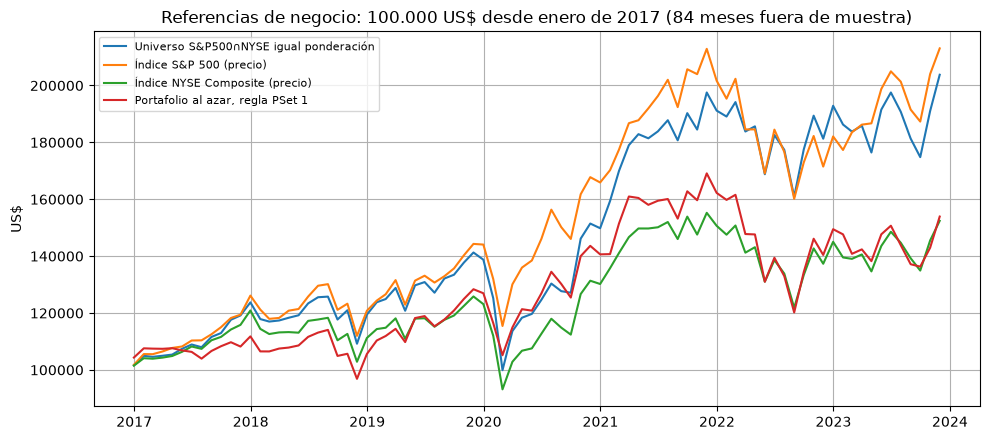

In [5]:
# Capital de 100.000 US$ invertido al inicio de 2017 con cada referencia (retorno neto de costos).
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, s in series.items():
    capital = 100_000 * (1 + s['neto']).cumprod()
    ax.plot(pd.PeriodIndex(s.index.astype(str), freq='M').to_timestamp() + pd.offsets.MonthEnd(1), capital, label=cortos[nombre])
ax.set_ylabel('US$'); ax.set_title('Referencias de negocio: 100.000 US$ desde enero de 2017 (84 meses fuera de muestra)')
ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(ROOT / 'docs/figuras/lineas_base_negocio.png', dpi=130, bbox_inches='tight'); plt.show()

In [6]:
# Vara que todo candidato debe superar (seccion 6): B1 en MAE y B5 en Sharpe neto.
vara = {'MAE de B1 (menor es mejor)': float(base_tecnica.set_index('modelo').loc['B1_media', 'mae_cv_media']),
        'MAE de B2 (menor es mejor)': float(base_tecnica.set_index('modelo').loc['B2_rw_cero', 'mae_cv_media']),
        'MAE de B3 (menor es mejor)': float(base_tecnica.set_index('modelo').loc['B3_rw_deriva', 'mae_cv_media']),
        'Sharpe neto de B3 (deriva por accion)': float(base_tecnica.set_index('modelo').loc['B3_rw_deriva', 'negocio_sharpe_neto']),
        'Sharpe neto de B5 (mayor es mejor)': float(tabla.loc['B5 universo S&P 500 ∩ NYSE, igual ponderación', 'sharpe_neto']),
        'Drawdown de B5 (referencia del error más costoso)': float(tabla.loc['B5 universo S&P 500 ∩ NYSE, igual ponderación', 'drawdown_max']),
        'Sharpe neto mediano de B4 (azar)': float(aleatorios.sharpe_neto.median())}
pd.Series(vara).round(4).to_frame('vara').to_csv(ROOT / 'docs/lineas_base.csv')
display(pd.Series(vara).round(4).to_frame('vara'))

,vara
MAE de B1 (menor es mejor),0.0641
MAE de B2 (menor es mejor),0.0647
MAE de B3 (menor es mejor),0.0652
Sharpe neto de B3 (deriva por accion),0.5849
Sharpe neto de B5 (mayor es mejor),0.5441
Drawdown de B5 (referencia del error más costoso),-0.2929
Sharpe neto mediano de B4 (azar),0.3443


**Lectura.**
- **Métrica técnica:** B1 y B2 tienen casi el mismo MAE (≈ 0,064). Predecir la media o predecir 0 es casi igual de
  bueno: el retorno del mes siguiente es casi ruido. Un candidato solo aporta si baja ese MAE.
- **Métrica de negocio:** B5 (todo el universo, igual ponderación) es la vara principal. Como ya vimos en el notebook
  03, un portafolio de 10 acciones con la regla del PSet 1 necesita elegir bien para superar a B5 después de costos.
  B4 dice cuánto se obtiene eligiendo al azar con la misma regla.
- **Índices:** el S&P 500 (Sharpe 0,63) queda **por encima** de B5 (0,54) aunque no incluye dividendos. En
  2017–2023 lo impulsaron las grandes tecnológicas de NASDAQ, que nuestro universo NYSE no puede comprar: es un costo
  de la restricción del universo, no del modelo, y se reporta como hallazgo. El NYSE Composite (0,34) queda por
  debajo, en parte por los dividendos y en parte porque incluye miles de acciones fuera del S&P 500. Ninguno de los
  dos es la vara del modelo.
- **B1 y B2 no tienen métrica de negocio:** una predicción constante no ordena acciones, y su referencia de negocio
  es B4.
- **B3 (deriva por acción):** su MAE (≈ 0,0652) es peor que el de B1, porque la media de 6–13 años de cada acción
  es ruidosa como pronóstico del mes siguiente. Pero sí ordena (IC ≈ 0,018) y, con la regla del PSet 1, su Sharpe
  neto (≈ 0,58) **supera a B5 (0,54)**: elegir las 10 acciones con mejor historia, ponderadas por 1/vol, ya le gana
  al universo. Es un hallazgo y sube la vara: un candidato que no le gane a B3 en Sharpe no aporta más que la
  historia de cada acción.

**Criterio para la sección 6:** todo candidato debe tener un MAE de CV menor que el de B1 **y** un Sharpe neto mayor
que el de B5, como pide el PDF. Además se compara con B3, la referencia más exigente. El que no lo logre se
documenta como hallazgo.

## 6. Modelos candidatos

**Sección 6 del PDF.** Entrena al menos 5 familias de modelos con sus hiperparámetros por defecto. Todos deben usar
la misma preparación, la misma validación y la misma métrica. Para cada modelo, reporta la métrica en entrenamiento
y en CV, la brecha entre ambas y el tiempo de entrenamiento, y usa esos números para diagnosticar el sobreajuste.
Además, prueba un LLM mediante prompting; si el problema no se puede plantear de esa forma, explica por qué.

| Familia del PDF | Modelo | Clave (tag `modelo`) | Tag `familia` |
|---|---|---|---|
| Lineal regularizado | Ridge | `M4_ridge` | `lineal` |
| Bagging | Random forest | `M2_random_forest` | `bagging` |
| Boosting | LightGBM y XGBoost (este último lo nombra el PSet 1) | `M3_lightgbm`, `M3b_xgboost` | `boosting` |
| Red neuronal | MLP | `M5_mlp` | `red_neuronal` |
| State of the Art | Chronos-Bolt, TimesFM y Moirai en zero-shot | `M8_chronos`, `M9_timesfm`, `M10_moirai` | `fundacional` |

Los tabulares usan exactamente el Pipeline de `src/pipeline.py`, con hiperparámetros por defecto y solo la semilla
42 fijada. Los fundacionales no se entrenan (zero-shot): reciben la serie diaria de cada acción hasta el cierre del
mes, pero se evalúan en los **mismos meses** de validación y con la **misma métrica**.

In [7]:
# 6.1 Tabulares (cuatro familias) con hiperparametros por defecto, misma preparacion, validacion y metrica.
TABULARES = ['M2_random_forest', 'M3_lightgbm', 'M3b_xgboost', 'M4_ridge', 'M5_mlp']
if REGISTRAR:
    tabulares = evaluar_candidatos(train, metadata, riesgo, metadata_dia, nombres=TABULARES)
else:
    tabulares = pd.read_csv(ROOT / 'docs/candidatos.csv').query('modelo in @TABULARES')
cols = ['modelo', 'familia', 'mae_train_cv', 'mae_cv_media', 'mae_cv_std', 'brecha_mae', 'segundos_entrenamiento',
        'ic_media', 'ic_t', 'negocio_sharpe_neto', 'negocio_drawdown_max', 'run_id']
display(tabulares[cols].round(4))

,modelo,familia,mae_train_cv,mae_cv_media,mae_cv_std,brecha_mae,segundos_entrenamiento,ic_media,ic_t,negocio_sharpe_neto,negocio_drawdown_max,run_id
3,M2_random_forest,bagging,0.0149,0.0757,0.0247,0.0608,205.9746,-0.0001,-0.0055,0.2014,-0.3392,3e899513e63e42d48ea01927c443240d
4,M3_lightgbm,boosting,0.0387,0.0706,0.0223,0.0319,13.4185,-0.0009,-0.0476,0.4404,-0.3641,c106ba8c4d4b4981975ea5a56cb262c3
5,M3b_xgboost,boosting,0.0300,0.0732,0.0202,0.0432,7.5753,-0.0042,-0.2827,0.4898,-0.2923,f3217499c2c74b3cabdf2cdaccda401a
6,M4_ridge,lineal,0.0513,0.0681,0.0200,0.0167,1.4680,-0.0319,-2.4441,0.1966,-0.2648,031156609d9a42c298b8b399d305b280
7,M5_mlp,red_neuronal,0.0449,0.0896,0.0189,0.0447,16.1736,-0.0177,-1.0739,0.2846,-0.3233,5056d83e572f42c4a420b6090f5afaed


Brecha de B1 (no aprende): 0.0112; se resta para diagnosticar el sobreajuste.


,familia,mae_train_cv,mae_cv_media,brecha_mae,segundos_entrenamiento,ic_media,negocio_sharpe_neto,brecha_sobre_B1,diagnostico,supera_B1_en_MAE,supera_B5_en_Sharpe,supera_B3_en_Sharpe
modelo,,,,,,,,,,,,
M2_random_forest,bagging,0.0149,0.0757,0.0608,205.9746,-0.0001,0.2014,0.0496,sobreajuste fuerte,False,False,False
M3_lightgbm,boosting,0.0387,0.0706,0.0319,13.4185,-0.0009,0.4404,0.0207,sobreajuste fuerte,False,False,False
M3b_xgboost,boosting,0.0300,0.0732,0.0432,7.5753,-0.0042,0.4898,0.0320,sobreajuste fuerte,False,False,False
M4_ridge,lineal,0.0513,0.0681,0.0167,1.4680,-0.0319,0.1966,0.0055,sobreajuste moderado,False,False,False
M5_mlp,red_neuronal,0.0449,0.0896,0.0447,16.1736,-0.0177,0.2846,0.0335,sobreajuste fuerte,False,False,False


HALLAZGO M2_random_forest: no supera a las dos lineas base (MAE 0.0757 vs B1 0.0641; Sharpe 0.20 vs B5 0.54).
HALLAZGO M3_lightgbm: no supera a las dos lineas base (MAE 0.0706 vs B1 0.0641; Sharpe 0.44 vs B5 0.54).
HALLAZGO M3b_xgboost: no supera a las dos lineas base (MAE 0.0732 vs B1 0.0641; Sharpe 0.49 vs B5 0.54).
HALLAZGO M4_ridge: no supera a las dos lineas base (MAE 0.0681 vs B1 0.0641; Sharpe 0.20 vs B5 0.54).
HALLAZGO M5_mlp: no supera a las dos lineas base (MAE 0.0896 vs B1 0.0641; Sharpe 0.28 vs B5 0.54).


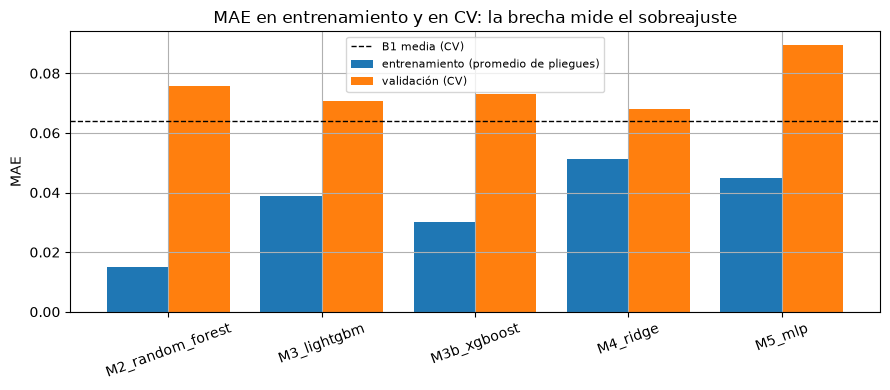

In [8]:
# 6.2 Diagnostico de sobreajuste y comparacion con las lineas base (la vara de la seccion 5).
base = pd.read_csv(ROOT / 'docs/candidatos.csv').set_index('modelo')
diag = tabulares.set_index('modelo')[['familia', 'mae_train_cv', 'mae_cv_media', 'brecha_mae', 'segundos_entrenamiento',
                                      'ic_media', 'negocio_sharpe_neto']].copy()
# Incluso B1 (sin aprender nada) tiene brecha: los anios de validacion (2017-2023, con 2020 y 2022) son mas
# volatiles que el promedio del entrenamiento. El sobreajuste es la brecha QUE EXCEDE la de B1.
brecha_b1 = float(base.loc['B1_media', 'brecha_mae'])
diag['brecha_sobre_B1'] = diag.brecha_mae - brecha_b1
diag['diagnostico'] = np.select([diag.brecha_sobre_B1 > 0.015, diag.brecha_sobre_B1 > 0.004],
                                ['sobreajuste fuerte', 'sobreajuste moderado'], 'sin sobreajuste notable')
print(f'Brecha de B1 (no aprende): {brecha_b1:.4f}; se resta para diagnosticar el sobreajuste.')
diag['supera_B1_en_MAE'] = diag.mae_cv_media < vara['MAE de B1 (menor es mejor)']
diag['supera_B5_en_Sharpe'] = diag.negocio_sharpe_neto > vara['Sharpe neto de B5 (mayor es mejor)']
diag['supera_B3_en_Sharpe'] = diag.negocio_sharpe_neto > vara['Sharpe neto de B3 (deriva por accion)']
display(diag.round(4))
diag.to_csv(ROOT / 'docs/diagnostico_candidatos.csv')
for m, f in diag.iterrows():
    if not (f.supera_B1_en_MAE and f.supera_B5_en_Sharpe):
        print(f'HALLAZGO {m}: no supera a las dos lineas base '
              f'(MAE {f.mae_cv_media:.4f} vs B1 {vara["MAE de B1 (menor es mejor)"]:.4f}; '
              f'Sharpe {f.negocio_sharpe_neto:.2f} vs B5 {vara["Sharpe neto de B5 (mayor es mejor)"]:.2f}).')

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(diag))
ax.bar(x - 0.2, diag.mae_train_cv, 0.4, label='entrenamiento (promedio de pliegues)')
ax.bar(x + 0.2, diag.mae_cv_media, 0.4, label='validación (CV)')
ax.axhline(vara['MAE de B1 (menor es mejor)'], color='k', ls='--', lw=1, label='B1 media (CV)')
ax.set_xticks(x, diag.index, rotation=20); ax.set_ylabel('MAE'); ax.legend(fontsize=8)
ax.set_title('MAE en entrenamiento y en CV: la brecha mide el sobreajuste')
plt.tight_layout(); fig.savefig(ROOT / 'docs/figuras/candidatos_brecha.png', dpi=130, bbox_inches='tight'); plt.show()

### 6.3 State of the Art: modelos fundacionales en zero-shot (M8–M10)

| Clave | Modelo (Hugging Face) | Paquete | Parámetros |
|---|---|---|---|
| `M8_chronos` | `amazon/chronos-bolt-small` | `chronos-forecasting` | ~48 M |
| `M9_timesfm` | `google/timesfm-2.5-200m-pytorch` | `timesfm[torch]` | ~200 M |
| `M10_moirai` | `Salesforce/moirai-2.0-R-small` | `uni2ts` (GitHub) | ~11 M |

**Cómo se usan:**
- **Entrada:** para cada fila (acción, mes *t*), los últimos 512 retornos log diarios **hasta el cierre de *t***, de
  `OBT_ACCION_DIA` y sin días imputados.
- **Pronóstico:** los 21 días hábiles siguientes. La predicción del mes es la suma de las medianas diarias, que es el
  retorno log del mes, igual que el objetivo. Los modelos normalizan cada ventana por su cuenta, así que no se ajusta
  nada con datos futuros.
- **Ejecución:** cada modelo corre una vez, en su propio entorno, porque sus paquetes chocan entre sí:
  `python -m src.modelos.fundacionales --modelo chronos|timesfm|moirai` (ver README). Deja
  `artefactos/fundacional_<modelo>.parquet` con su SHA-256.
- **Evaluación:** con los mismos pliegues y las mismas métricas que los tabulares (`registrar_fundacional`). Al no
  entrenarse, el "MAE de entrenamiento" es el de los meses de entrenamiento de cada pliegue, y su brecha **no** mide
  sobreajuste. El tiempo que se reporta es el de inferencia.
- **Riesgo de contaminación:** si el corpus de preentrenamiento incluye precios de acciones del periodo evaluado, el
  resultado es optimista. Ninguno de los tres garantiza que su corpus excluya precios de acciones de EE. UU. de
  2017–2026, así que se reporta como limitación.

In [9]:
# Registra los fundacionales cuyos pronosticos existen; si alguno no pudo correr, se documenta el motivo.
FUNDACIONALES = {'M8_chronos': 'chronos', 'M9_timesfm': 'timesfm', 'M10_moirai': 'moirai'}
disponibles = [m for m, c in FUNDACIONALES.items() if (ROOT / f'artefactos/fundacional_{c}.parquet').exists()]
for m, c in FUNDACIONALES.items():
    ruta = ROOT / f'artefactos/fundacional_{c}.json'
    print(f'{m}: ' + (ruta.read_text().replace(chr(10), ' ') if ruta.exists() else 'sin pronosticos (no se pudo correr; ver README)'))
if REGISTRAR and disponibles:
    fundacionales = evaluar_candidatos(train, metadata, riesgo, metadata_dia, nombres=disponibles)
else:
    fundacionales = pd.read_csv(ROOT / 'docs/candidatos.csv').query('modelo in @disponibles')
if len(fundacionales):
    display(fundacionales[['modelo', 'familia', 'mae_train_cv', 'mae_cv_media', 'mae_cv_std', 'segundos_inferencia',
                           'cobertura', 'ic_media', 'ic_t', 'negocio_sharpe_neto', 'negocio_drawdown_max', 'run_id']].round(4))

M8_chronos: {   "modelo": "chronos",   "id": "amazon/chronos-bolt-small",   "contexto": 512,   "horizonte_dias": 21,   "filas": 58627,   "latencia_ms_por_serie": 0.2543179934176006,   "segundos_carga": 6.431452166987583,   "segundos_total": 22.757985333912075,   "sha256": "9e6281bdd4f793db872e1ff1bd5e1da4d88600b228840b6030bfa0bdc4617376" }
M9_timesfm: {   "modelo": "timesfm",   "id": "google/timesfm-2.5-200m-pytorch",   "desde": 201612,   "hasta": 202311,   "contexto": 512,   "horizonte_dias": 21,   "filas": 26750,   "latencia_ms_por_serie": 107.5464140685606,   "segundos_carga": 5.798946249997243,   "segundos_total": 2883.552877624985,   "sha256": "343ad46dd538578872cb30d5d211271cc460771d88f527a6c8b95cb51ae41d18" }
M10_moirai: {   "modelo": "moirai",   "id": "Salesforce/moirai-2.0-R-small",   "desde": null,   "hasta": null,   "contexto": 512,   "horizonte_dias": 21,   "filas": 58627,   "latencia_ms_por_serie": 4.047408641359698,   "segundos_carga": 11.295534583972767,   "segundos_tota

,modelo,familia,mae_train_cv,mae_cv_media,mae_cv_std,segundos_inferencia,cobertura,ic_media,ic_t,negocio_sharpe_neto,negocio_drawdown_max,run_id
8,M8_chronos,fundacional,0.0550,0.0670,0.0175,22.7580,1.0,-0.0253,-1.1233,0.5682,-0.2212,cae84206dd404618b1812618eb5b6e3b
9,M10_moirai,fundacional,0.0563,0.0693,0.0192,252.2736,1.0,-0.0171,-0.8009,0.4302,-0.2278,d3cdca347b8c49dbafe3636a5a55bfe1
10,M9_timesfm,fundacional,0.0578,0.0687,0.0171,2883.5529,1.0,-0.0110,-0.5051,0.4569,-0.2215,eff5db0428384e13979a22a98a8e0e78


**Nota sobre M9 TimesFM.** La primera corrida registrada de TimesFM (`11ba2e86…`) usó un archivo de prueba de 500
filas, con una cobertura de 0,94 % de la validación. Su MAE (0,0641) no era comparable. Se reemplazó por la corrida
`eff5db04…`, con 26.750 pronósticos de los meses de validación, y la inválida quedó en MLflow con
`fase = descartada`. Detalle en [`docs/corridas_descartadas.md`](../docs/corridas_descartadas.md).


In [10]:
# 6.5 Tabla final de candidatos frente a las lineas base (las 5 familias del PDF).
todos = pd.read_csv(ROOT / 'docs/candidatos.csv')
orden = BASES + TABULARES + list(FUNDACIONALES)
todos = todos[todos.modelo.isin(orden)].set_index('modelo').reindex([m for m in orden if m in set(todos.modelo)])
tabla_final = todos[['familia', 'mae_train_cv', 'mae_cv_media', 'mae_cv_std', 'brecha_mae', 'ic_media',
                     'negocio_sharpe_neto', 'negocio_drawdown_max']].copy()
tabla_final['supera_B1_MAE'] = tabla_final.mae_cv_media < vara['MAE de B1 (menor es mejor)']
tabla_final['supera_B5_Sharpe'] = tabla_final.negocio_sharpe_neto > vara['Sharpe neto de B5 (mayor es mejor)']
display(tabla_final.round(4))
print('Familias cubiertas:', sorted(set(tabla_final.familia) - {'linea_base'}))

,familia,mae_train_cv,mae_cv_media,mae_cv_std,brecha_mae,ic_media,negocio_sharpe_neto,negocio_drawdown_max,supera_B1_MAE,supera_B5_Sharpe
modelo,,,,,,,,,,
B1_media,linea_base,0.0529,0.0641,0.0165,0.0112,NaN,NaN,NaN,False,False
B2_rw_cero,linea_base,0.0539,0.0647,0.0159,0.0108,NaN,NaN,NaN,False,False
B3_rw_deriva,linea_base,0.0527,0.0652,0.0159,0.0126,0.0184,0.5849,-0.2632,False,True
M2_random_forest,bagging,0.0149,0.0757,0.0247,0.0608,-0.0001,0.2014,-0.3392,False,False
M3_lightgbm,boosting,0.0387,0.0706,0.0223,0.0319,-0.0009,0.4404,-0.3641,False,False
M3b_xgboost,boosting,0.0300,0.0732,0.0202,0.0432,-0.0042,0.4898,-0.2923,False,False
M4_ridge,lineal,0.0513,0.0681,0.0200,0.0167,-0.0319,0.1966,-0.2648,False,False
M5_mlp,red_neuronal,0.0449,0.0896,0.0189,0.0447,-0.0177,0.2846,-0.3233,False,False
M8_chronos,fundacional,0.0550,0.0670,0.0175,0.0120,-0.0253,0.5682,-0.2212,False,True


Familias cubiertas: ['bagging', 'boosting', 'fundacional', 'lineal', 'red_neuronal']


### 6.4 LLM por prompting: por qué este problema no se plantea bien así

El PDF pide probar un LLM por prompting o explicar por qué no se puede. **No se prueba, por tres razones:**
1. **Fuga de información inevitable.** Un LLM (GPT, Claude, Gemini) se entrenó con texto de internet que incluye los
   precios, noticias y resultados de estas mismas acciones en 2017–2023 y en el hold-out (2024–2026). Si se le pide
   el retorno de una acción en un mes, puede "recordar" lo que pasó en lugar de pronosticarlo, y no hay forma de
   cortar su conocimiento en la fecha *t*. Cualquier resultado sería optimista y no serviría como evidencia, que es
   justamente lo que el PDF prohíbe ("una feature que no existe en el momento de la predicción es data leakage").
2. **El formato no encaja.** Cada mes hay que ordenar ~330 acciones con 35 variables numéricas: 26.696 pronósticos
   solo en validación. Pasar tablas numéricas por texto es caro, lento y poco fiable (los LLM no hacen aritmética
   exacta sobre miles de números) y no es reproducible con semilla.
3. **Ya hay un fundacional adecuado.** La familia State of the Art se cubre con modelos fundacionales **de series de
   tiempo** (Chronos, TimesFM, Moirai), entrenados para pronosticar números y no texto, y que se pueden cortar
   exactamente en la fecha *t*.

Uso legítimo de un LLM en este proyecto, fuera de la evaluación: explicarle al asesor en lenguaje natural por qué se
propone cada portafolio, a partir de las variables del modelo. Queda como idea para el PSet 4.

### 6.6 Modelos del PSet 1 que no entran en esta entrega

ARIMA por acción (M1) y los híbridos ARIMA + MLP (M6) y ARIMA + LSTM (M7) tienen código en `src/modelos/series.py` y
`src/modelos/redes.py`, pero no se corren hoy por tiempo de cómputo y de integración. Las cinco familias del PDF ya
quedan cubiertas, y estos modelos quedan como trabajo para el PSet 4.